---

# Optimización del entrenamiento: Gradient Clipping y Learning Rate Schedule

Hay varios hiperparámetros que se pueden aplicar para ajustar el proceso de descenso del gradiente (*Gradient Descent*). Los más utilizados son el **Gradient Clipping** y el **Learning Rate Schedule**. Ambos son conceptos que se aplican con frecuencia cuando se entrenan modelos grandes (como arquitecturas basadas en Transformers o redes profundas complejas). Por otro lado, estas no son técnicas que se necesiten utilizar para la mayoría de los modelos de *deep learning* pequeños o incluso medianos.

El **Clipping** (o recorte) es un término general utilizado en la ciencia de datos, el procesamiento de señales y otras aplicaciones relacionadas con datos en las que pueden existir valores extremos que resulten perjudiciales para el análisis. Veamos un ejemplo sencillo:

| Datos Originales | Con Clipping (Umbral = 10) |
| --- | --- |
| 1 | 1 |
| 2 | 2 |
| -4 | -4 |
| 0 | 0 |
| **99** | **10** |
| 3 | 3 |
| 2 | 2 |
| 8 | 8 |

Imaginemos que la primera columna de la izquierda es un vector de puntos de datos. Está claro que el valor `99` es un valor atípico o extremo (*outlier*). Si definimos un *Clipping Threshold* (umbral de recorte) de `10`, la idea es que cualquier valor en este conjunto de datos que sea mayor que diez se restablece o limita a diez, tal como se observa en la columna de la derecha.

Esta técnica se utiliza para reducir el impacto de los valores atípicos en las estadísticas, las características de los datos, el filtrado o cualquier análisis que se vaya a aplicar. Cabe destacar que este ejemplo inicial no trata sobre el *Gradient Clipping*, sino de la conceptualización general del recorte.

---

## Aplicación específica: Gradient Clipping en Deep Learning

Específicamente con respecto al **Gradient Clipping** en el entrenamiento de redes profundas (*deep learning*), la idea central cambia: **no se busca recortar valores individuales de los datos, sino recortar los gradientes**.

Los gradientes son las derivadas de la función de pérdida con respecto a los pesos del modelo, y se utilizan para actualizar dichos pesos escalados por la tasa de aprendizaje (*learning rate*). Si por alguna razón el modelo se vuelve numéricamente inestable —tal vez debido a la acumulación de números muy grandes que se multiplican sucesivamente a través de las capas—, el gradiente puede crecer desproporcionadamente hasta **explotar (*Exploding Gradient*)**. Esto puede corromper los pesos con valores `NaN` (Not a Number) y causar un fallo catastrófico en el entrenamiento del modelo.

### ¿Cómo funciona y cuáles son los umbrales habituales?

La idea del *Gradient Clipping* es reescalar o normalizar la norma del vector de gradientes para que no supere un valor de umbral (*threshold*) predeterminado.

* **Valores típicos utilizados en la práctica:** En modelos de lenguaje y redes neuronales profundas, los valores más comunes para el umbral de recorte (*clip norm*) suelen situarse entre **`1.0` y `5.0**` (por ejemplo, es muy estándar configurar un límite de `1.0` en arquitecturas tipo Transformer). Si la norma global de los gradientes supera este valor, se reducen proporcionalmente para ajustarse al límite.

---

### El equilibrio entre estabilidad e información

Ahora bien, un aspecto fundamental a considerar es que **las magnitudes de los gradientes contienen información real y significativa para el aprendizaje**. Cuando un gradiente es grande, indica que el modelo está lejos del óptimo y los parámetros deben cambiar drásticamente; cuando es pequeño, los cambios deben ser sutiles.

Por esta razón, aplicar un recorte arbitrario implica modificar la dirección o magnitud original de la actualización, lo que técnicamente puede suponer una pérdida parcial de información direccional y **ralentizar temporalmente el aprendizaje**.

Sin embargo, el balance beneficia al proceso: si los gradientes explotan y el modelo se vuelve tan inestable numéricamente que colapsa por completo, ralentizar el aprendizaje o limitar el paso mediante el recorte es una solución sumamente efectiva para garantizar la convergencia del modelo.

---

## Learning Rate Schedule (Programador de la Tasa de Aprendizaje)

En el entrenamiento tradicional de modelos de *deep learning*, la tasa de aprendizaje (*learning rate*) suele establecerse en un valor fijo durante todo el proceso. Ahora bien, aunque se utilice un optimizador como **Adam** —en el cual la tasa efectiva de aprendizaje se modifica dinámicamente según el histórico reciente y la varianza de los gradientes—, un programador de la tasa de aprendizaje (**Learning Rate Schedule**) añade restricciones y esquemas de control adicionales sobre la tasa máxima posible.

### ¿Cómo funciona en la práctica?

Un ejemplo clásico es el esquema de **warmup lineal**: la tasa de aprendizaje comienza en `0` (o muy cerca de cero), aumenta de forma lineal durante un número determinado de épocas de entrenamiento y posteriormente puede seguir una estrategia de decaimiento (*decay*).

En general, programar o aplicar un *Learning Rate Schedule* de forma dinámica es otra técnica que **no suele ser necesaria para modelos pequeños o medianos**, pero resulta fundamental y ayuda enormemente con modelos grandes. Al igual que el *Gradient Clipping*, la idea subyacente es estabilizar el proceso de optimización —ralentizando el aprendizaje cuando es necesario para evitar divergencias numéricas—, incluso si esto implica que el entrenamiento requiera un poco más de tiempo.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import get_cosine_schedule_with_warmup, get_linear_schedule_with_warmup # vamos a destacar estas pero no son las unicas tecnicas de Lr que se pueden usar

# gráficos vectoriales
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

---

Ejemplo práctico de **Gradient Clipping**. Cabe destacar que este no es un modelo que se vaya a entrenar de forma real, por lo que podemos imaginar simplemente que estos valores representan los pesos de un modelo.

La función de pérdida (*loss function*) utilizada es simplemente la **norma L2** (es decir, la suma de los elementos al cuadrado).

Si estuviéramos entrenando este modelo iterativamente, lo que haría esta función de pérdida es entrenar al modelo para reducir progresivamente la magnitud de los pesos (y por ende de los gradientes de $w$), haciendo que la suma de los pesos al cuadrado se vuelva cada vez más pequeña en cada iteración.

In [5]:
# tensor con gradientes (como una matriz de pesos)
w = torch.tensor([[-1, 3.3, 2, -5, 3, -2, -4, -5, 1.5]], requires_grad=True)

# la pérdida es la suma de los cuadrados (L2)
loss = (w**2).sum()

# propagación hacia atrás (backprop)
loss.backward()

# imprimir los gradientes y su norma antes del recorte
print('ANTES DEL Cliping:')
print(f' Valores del gradiente: {w.grad[0].tolist()}')
print(f' Norma del gradiente: {torch.norm(w.grad):.3f}')

# aplicar el recorte de gradientes (gradient clipping)
preClipVals = w.grad[0].detach() + 0
nn.utils.clip_grad_norm_([w], max_norm=1) # no necesitamos una variable es una funcion in situ - donde pasamos la funcion, los tensores de Pytorch y la max_norm para saber que es in situ por el final de la funcion _

# imprimir los gradientes nuevamente
print('\nDESPUÉS DEL Cliping:')
print(f' Valores del gradiente: {w.grad[0].tolist()}')
print(f' Norma del gradiente: {torch.norm(w.grad):.3f}')

ANTES DEL Cliping:
 Valores del gradiente: [-2.0, 6.599999904632568, 4.0, -10.0, 6.0, -4.0, -8.0, -10.0, 3.0]
 Norma del gradiente: 19.712

DESPUÉS DEL Cliping:
 Valores del gradiente: [-0.10146141052246094, 0.3348226547241211, 0.20292282104492188, -0.5073070526123047, 0.3043842315673828, -0.20292282104492188, -0.40584564208984375, -0.5073070526123047, 0.1521921157836914]
 Norma del gradiente: 1.000


Pasamos de una norma de gradiente de 19.712 a exactamente 1.000, debido a que 1 es el umbral (threshold) máximo especificado (max_norm=1). Como la norma original superaba este límite, todos los gradientes se redujeron proporcionalmente para ajustarse a dicho valor.

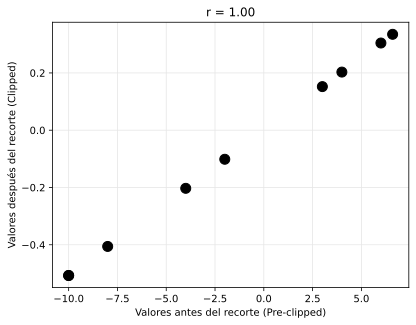

In [6]:
# su correlación
r = torch.corrcoef(torch.cat((preClipVals.unsqueeze(0), w.grad.detach()), dim=0))

plt.plot(preClipVals, w.grad.detach().squeeze(), 'ko', markersize=10)
plt.gca().set(xlabel='Valores antes del recorte (Pre-clipped)',
              ylabel='Valores después del recorte (Clipped)',
              title=f'r = {r[0,1]:.2f}')
plt.grid(color=[.9, .9, .9])
plt.show()

Como se puede observar en el gráfico, el coeficiente de correlación de Pearson es exactamente **$r = 1.00$**.

A nivel técnico, es importante matizar un detalle: los valores individuales **sí se modifican en su magnitud absoluta** (ya que todos se reducen de tamaño), pero **no cambian su proporción relativa ni su dirección**.

Esto ocurre porque el *gradient clipping* basado en la norma no altera los elementos de forma independiente o arbitraria; en su lugar, toma todo el vector de gradientes y lo escala de manera uniforme dividiendo sus componentes por un mismo factor de proporcionalidad.

Como resultado de este reescalado global:

* Los puntos se alinean perfectamente en una línea recta perfecta en el diagrama de dispersión ($r = 1.00$).


* Esto demuestra una de las mayores ventajas del recorte de gradientes: **preserva la dirección de la información del gradiente** (la ruta de aprendizaje que el modelo necesita), pero reduce su tamaño total de forma controlada para que la norma final coincida exactamente con el umbral establecido (`max_norm=1`), evitando así la explosión de gradientes sin distorsionar el sentido físico de los datos.

In [7]:
# 1. Configuración inicial del entrenamiento (80 iteraciones o pasos)
training_steps = 80

# Definir una matriz de pesos simulada (requires_grad=True para rastrear gradientes)
# Imaginemos que este es un modelo simplificado con dos tokens o logits de salida.
w = torch.tensor([[-4.0, 2.0]], requires_grad=True)

# Categoría objetivo (target): queremos que el modelo aprenda a seleccionar
# el primer token (el que corresponde al índice 0).
target = torch.tensor([0])

# Configurar la función de pérdida (Negative Log Likelihood) y el optimizador (SGD)
loss_function = nn.NLLLoss()
optimizer = torch.optim.SGD([w], lr=0.03)

# Contenedores para almacenar el historial de los pesos y las normas de los gradientes
allWeights = torch.zeros((training_steps + 1, 2))
allWeights[0, :] = w.detach()
grad_norms = np.zeros((training_steps, 2))

# 2. Bucle principal de entrenamiento (itera a través de los 80 pasos)
for i in range(training_steps):

    # Reiniciar todos los gradientes acumulados a cero antes de cada iteración
    optimizer.zero_grad()

    # Pasada hacia adelante (Forward pass):
    # Calculamos las probabilidades log-softmax sobre los pesos actuales (simulando los logits finales).
    modeloutput = F.log_softmax(w, dim=1)

    # Calcular la pérdida (cu qué tan lejos estamos del objetivo deseado)
    loss = loss_function(modeloutput, target)

    # Retropropagación (Backward pass): calcular el gradiente de la pérdida con respecto a w
    loss.backward()

    # Almacenar la norma del gradiente original (sin recortar) para comparación
    grad_norms[i, 0] = torch.norm(w.grad).item()

    # --- APLICACIÓN DEL GRADIENT CLIPPING ---
    # Nota técnica: El recorte debe hacerse ANTES de optimizer.step() para que
    # el optimizador reciba los gradientes ya limitados y evite saltos numéricos bruscos.
    nn.utils.clip_grad_norm_([w], max_norm=1.0)

    # Almacenar la norma del gradiente DESPUÉS del recorte para visualizar el efecto
    grad_norms[i, 1] = torch.norm(w.grad).item()

    # Actualizar los pesos del modelo utilizando el optimizador (SGD)
    optimizer.step()

    # Guardar una copia de los nuevos pesos resultantes para graficar su trayectoria
    allWeights[i + 1, :] = w.detach()

print("Simulación de entrenamiento con Gradient Clipping completada con éxito!")

Simulación de entrenamiento con Gradient Clipping completada con éxito!


> *"En esta demostración específica, el propósito principal no es entrenar un modelo productivo de alta precisión, sino **medir y visualizar el impacto analítico** del recorte de gradientes. Si colocamos el `clip_grad_norm_` después de la actualización de pesos (o de forma aislada), podemos auditar y registrar con precisión matemática cómo se comportaba la norma original frente al umbral establecido de `1.0`, permitiéndonos graficar la diferencia exacta antes y después de aplicar la restricción."*

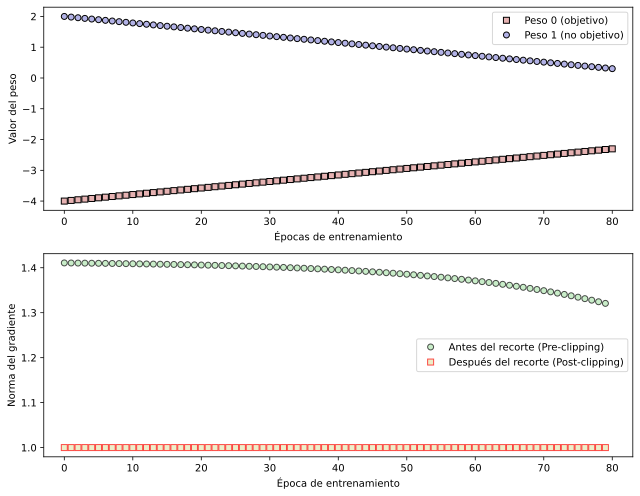

In [9]:
_, axs = plt.subplots(2, 1, figsize=(9, 7))

# Gráfico superior: Evolución de los pesos
axs[0].plot(allWeights[:, 0], 'ks', markerfacecolor=[.9, .7, .7], markersize=6, label='Peso 0 (objetivo)')
axs[0].plot(allWeights[:, 1], 'ko', markerfacecolor=[.7, .7, .9], markersize=6, label='Peso 1 (no objetivo)')
axs[0].set(xlabel='Épocas de entrenamiento', ylabel='Valor del peso', xlim=[-3, training_steps + 3])
axs[0].legend()

# Gráfico inferior: Normas de los gradientes
axs[1].plot(grad_norms[:, 0], 'ko', markerfacecolor=[.7, .9, .7], markersize=6, alpha=.7, label='Antes del recorte (Pre-clipping)')
axs[1].plot(grad_norms[:, 1], 'rs', markerfacecolor=[.9, .9, .7], markersize=6, alpha=.7, label='Después del recorte (Post-clipping)')
axs[1].set(xlabel='Época de entrenamiento', ylabel='Norma del gradiente', xlim=[-3, training_steps + 3])
axs[1].legend()

plt.tight_layout()
plt.show()

En este tipo de arquitecturas de clasificación, el modelo no busca un número fijo predeterminado (como decir "el peso ideal es exactamente 5").

Lo único que le importa a la función de pérdida (Softmax combinado con NLLLoss) es la diferencia numérica entre ambos. El modelo quiere que el peso de la clase correcta sea cada vez más grande en comparación con el de la incorrecta.

### ¿Qué nos está mostrando esta gráfica?

Imaginemos que entrenar un modelo de inteligencia artificial es como enseñarle a alguien a caminar por un camino lleno de curvas. Los **gradientes** son los "pasos" que da el modelo para corregir sus errores. Si da pasos demasiado gigantescos (una explosión de gradiente), se puede tropezar y arruinar todo el aprendizaje.

---

### 1. La gráfica de arriba (Los Pesos)

* **¿Qué vemos?** Vemos dos líneas formadas por pequeños puntos que se van moviendo a lo largo de las 80 épocas de entrenamiento.

* **En sencillo:** El modelo está cambiando poco a poco sus valores (o sus pesos) para aprender a acertar. El **Peso 0** va subiendo y el **Peso 1** va bajando de forma suave y ordenada gracias a que el entrenamiento avanza paso a paso sin volverse loco.


### 2. La gráfica de abajo (El poder del Recorte / Clipping)

Aquí es donde ocurre la magia del **Gradient Clipping**:

* **La línea verde de arriba ("Antes del recorte"):** Nos muestra el tamaño real que tendrían los pasos (la norma del gradiente) si dejáramos al modelo libre. Vemos que están por encima de 1.4.


* **La línea roja de abajo ("Después del recorte"):** Es el límite estricto que nosotros impusimos (`max_norm = 1.0`).
* **En sencillo:** Como los pasos originales eran más grandes de lo permitido (estaban en ~1.4), el sistema de recorte actúa como un **freno automático** y los aplana exactamente en la línea roja de **1.0** durante todo el entrenamiento.



### ¿En conclusión?

Esta gráfica demuestra visualmente que el *Gradient Clipping* funciona como un cinturón de seguridad: agarra los cambios que son muy grandes y los reduce a un tamaño seguro para evitar que el modelo falle o colapse.

In [10]:
# no es algo que se quiera hacer para modelos pequeños esto es algo que se puede hacer para modelos muy grandes que puedan ser inestables numericamente